# 02 · Rasgos de forma y estilo

Parte descriptiva de la pregunta P1: ¿qué rasgos de forma distinguen a cada género? Se describen los 45 rasgos de `src/rasgos.py` (41 lingüísticos en 8 grupos y 4 de transcripción como control) sobre la muestra de trabajo: cobertura del diccionario fonético, valores por género, separabilidad de cada rasgo por separado y relación con la longitud y el año, que pueden actuar como confusores. El aporte de cada grupo dentro de un modelo se mide en `03_modelos_rasgos.ipynb`.

Los rasgos se calculan con `python -m src.rasgos` (alrededor de 10 minutos) y quedan en `data/processed/rasgos.parquet`. Este notebook solo los lee y tarda menos de un minuto. Las figuras se guardan en `reports/figures` y las tablas en `reports/tablas`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.datos import GENEROS
from src.rasgos import GRUPOS, NOMBRE_GRUPO

PROC = RAIZ / "data" / "processed"
FIG = RAIZ / "reports" / "figures"
TAB = RAIZ / "reports" / "tablas"
assert (PROC / "rasgos.parquet").exists(), "Falta rasgos.parquet; se genera con `python -m src.rasgos`"

pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.3f}".format)

NOMBRE = {"pop": "Pop", "rap": "Rap", "rock": "Rock", "rb": "R&B", "country": "Country"}
COLOR = {"pop": "#2a78d6", "rap": "#eb6834", "rock": "#1baf7a", "rb": "#eda100", "country": "#e87ba4"}
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 9, "axes.titlesize": 9.5, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.edgecolor": TINTA_2, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "text.color": TINTA, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False, "font.family": "Arial",
})


def guardar(fig, nombre):
    fig.savefig(FIG / f"{nombre}.png", bbox_inches="tight", facecolor="white")


muestra = pd.read_parquet(PROC / "muestra.parquet", columns=["id", "tag", "artist", "year"])
df = muestra.merge(pd.read_parquet(PROC / "rasgos.parquet"), on="id", validate="1:1")
COLS = [c for cols in GRUPOS.values() for c in cols]
GRUPO_DE = {c: g for g, cols in GRUPOS.items() for c in cols}
print(f"{len(df):,} canciones, {len(COLS)} rasgos en {len(GRUPOS)} grupos")
pd.Series({f"{g} · {NOMBRE_GRUPO[g]}": len(cols) for g, cols in GRUPOS.items()}, name="rasgos").to_frame()

50,000 canciones, 45 rasgos en 9 grupos


,rasgos
E · estructura,6
R · repetición,4
S · rima y sonido,7
M · métrica,3
D · diversidad léxica,4
P · pronombres,5
O · oralidad y registro,6
X · sintaxis,6
T · transcripción (control),4


## 1. Cobertura del diccionario fonético y valores faltantes

Las medidas de rima usan las pronunciaciones del diccionario CMU. Una palabra fuera del diccionario (jerga, nombres propios, palabras inventadas) no participa de la rima. Si una letra tiene menos de tres pares de versos válidos, la medida queda como faltante en lugar de calcularse sobre muy pocos datos. XGBoost trata los faltantes de forma nativa, pero conviene saber cuántos hay y si se concentran en algún género.

In [2]:
cobertura = df.groupby("tag")["o_cobertura_cmu"].agg(
    mediana="median", p10=lambda s: s.quantile(0.1), menos_de_80=lambda s: (s < 0.8).mean() * 100
).reindex(GENEROS).rename(index=NOMBRE)
cobertura.columns = ["cobertura mediana", "percentil 10", "% de letras con cobertura < 80%"]
display(cobertura)

faltantes = df[COLS].isna().groupby(df["tag"]).mean().T.mul(100)[GENEROS].rename(columns=NOMBRE)
faltantes[faltantes.max(axis=1) > 0].round(1).rename_axis("% de letras sin valor")

,cobertura mediana,percentil 10,% de letras con cobertura < 80%
tag,,,
Pop,0.996,0.958,0.980
Rap,0.969,0.921,1.100
Rock,1.000,0.972,0.270
R&B,0.991,0.951,0.540
Country,0.997,0.976,0.320


tag,Pop,Rap,Rock,R&B,Country
% de letras sin valor,,,,,
r_trigramas_repetidos,0.000,0.000,0.000,0.000,0.000
s_rima_AA,1.200,2.300,1.300,1.100,0.700
s_rima_ABAB,1.800,2.800,1.800,1.600,0.900
s_densidad_rima,0.900,1.900,1.100,0.800,0.600
s_densidad_multisilabica,0.900,2.000,1.200,0.900,0.600
s_densidad_asonancia,0.900,2.000,1.200,0.900,0.600
s_rima_interna,3.400,1.800,3.600,2.000,1.200
s_aliteracion,1.200,0.400,0.900,0.800,0.200
m_pct_acentuadas,0.000,0.000,0.000,0.000,0.000


## 2. Valores por género

Mediana de cada rasgo por género. Las tasas de pronombres, oralidad y negación están expresadas cada 100 palabras; las de rima y repetición, como proporciones entre 0 y 1.

In [3]:
medianas = df.groupby("tag")[COLS].median().T[GENEROS].rename(columns=NOMBRE)
medianas.insert(0, "grupo", [GRUPO_DE[c] for c in medianas.index])
medianas.to_csv(TAB / "rasgos_medianas_por_genero.csv")
medianas

tag,grupo,Pop,Rap,Rock,R&B,Country
e_log_palabras,E,5.425,6.006,5.226,5.642,5.407
e_log_versos,E,3.611,3.989,3.434,3.784,3.466
e_palabras_por_verso,E,6.178,7.775,6.062,6.438,7.103
e_cv_palabras_por_verso,E,0.349,0.362,0.341,0.373,0.291
e_estrofas,E,6.000,5.000,6.000,6.000,6.000
e_versos_por_estrofa,E,5.400,10.000,5.000,6.551,5.200
r_pct_versos_repetidos,R,33.333,16.418,25.000,29.630,28.125
r_compresion,R,0.339,0.400,0.391,0.336,0.362
r_estribillo,R,0.300,0.174,0.250,0.263,0.298
r_trigramas_repetidos,R,0.345,0.178,0.255,0.327,0.302


## 3. Separabilidad de cada rasgo por separado

Para cada rasgo y género se calcula el AUC uno contra el resto: la probabilidad de que una canción del género tenga un valor más alto que una de otro género. 0,5 indica que el rasgo no separa; valores mayores, que el género tiende a tener valores más altos, y menores, más bajos. Es una medida univariada y sin modelo: no captura combinaciones de rasgos ni descuenta la redundancia entre ellos, cosas que se analizan en el notebook 03 con la ablación por grupos.

In [4]:
def auc_uno_contra_resto(col, genero):
    ok = df[col].notna()
    return roc_auc_score(df.loc[ok, "tag"] == genero, df.loc[ok, col])


auc = pd.DataFrame({NOMBRE[g]: {c: auc_uno_contra_resto(c, g) for c in COLS} for g in GENEROS})
auc.insert(0, "grupo", [GRUPO_DE[c] for c in auc.index])
auc.to_csv(TAB / "rasgos_auc_por_genero.csv")

# Los tres rasgos que más separan a cada género (mayor |AUC - 0,5|), con el signo de la diferencia.
filas = {}
for g in GENEROS:
    d = (auc[NOMBRE[g]] - 0.5).abs().nlargest(3).index
    filas[NOMBRE[g]] = [f"{c} ({auc.loc[c, NOMBRE[g]]:.2f})" for c in d]
pd.DataFrame(filas, index=["1°", "2°", "3°"]).T

,1°,2°,3°
Pop,r_pct_versos_repetidos (0.61),r_trigramas_repetidos (0.61),m_silabas_por_verso (0.39)
Rap,o_groserias (0.82),o_cobertura_cmu (0.19),e_log_palabras (0.78)
Rock,e_log_palabras (0.31),o_coloquial (0.31),e_log_versos (0.36)
R&B,m_pct_acentuadas (0.66),d_mtld (0.35),p_tu (0.65)
Country,m_cv_silabas (0.33),e_cv_palabras_por_verso (0.34),o_cobertura_cmu (0.64)


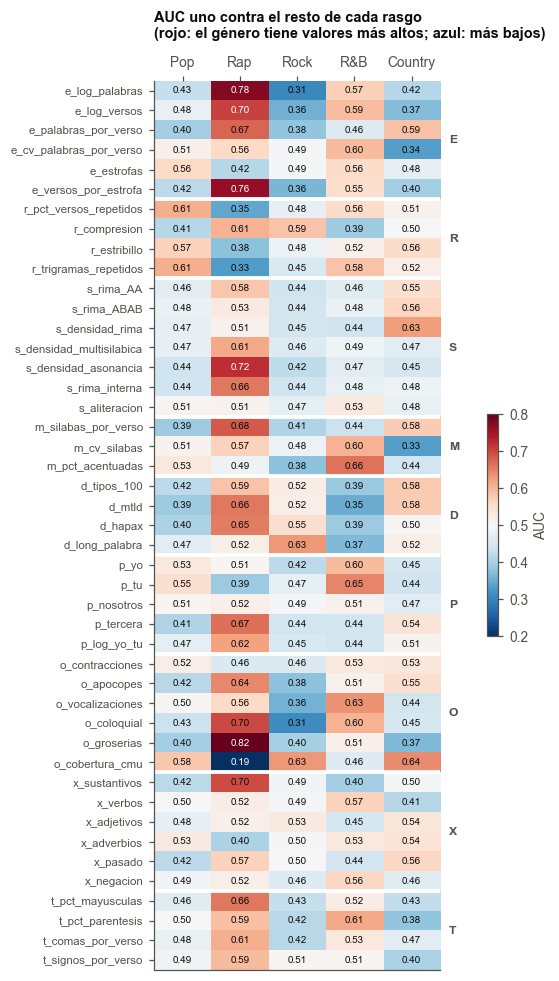

In [5]:
valores = auc[[NOMBRE[g] for g in GENEROS]].to_numpy()
fig, ax = plt.subplots(figsize=(4.6, 10.5))
im = ax.imshow(valores, cmap="RdBu_r", vmin=0.2, vmax=0.8, aspect="auto")
ax.set_xticks(range(len(GENEROS)), [NOMBRE[g] for g in GENEROS])
ax.xaxis.tick_top()
ax.set_yticks(range(len(COLS)), COLS, fontsize=7.5)
for i in range(valores.shape[0]):
    for j in range(valores.shape[1]):
        ax.text(j, i, f"{valores[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(valores[i, j] - 0.5) > 0.2 else TINTA)
limites = np.cumsum([len(cols) for cols in GRUPOS.values()])[:-1]
for y in limites:
    ax.axhline(y - 0.5, color="white", lw=2.5)
for g, cols in GRUPOS.items():
    centro = COLS.index(cols[0]) + (len(cols) - 1) / 2
    ax.text(len(GENEROS) - 0.35, centro, g, ha="left", va="center", fontsize=8, fontweight="bold", color=TINTA_2)
ax.grid(False)
ax.set_title("AUC uno contra el resto de cada rasgo\n(rojo: el género tiene valores más altos; azul: más bajos)", pad=28)
fig.colorbar(im, ax=ax, shrink=0.25, pad=0.12, label="AUC")
guardar(fig, "rasgos_auc_por_genero")

## 4. Rasgos que pueden confundir: longitud y año

Dos chequeos previos a los modelos:

- **Longitud.** Correlación de Spearman de cada rasgo con el logaritmo de la cantidad de palabras. Un rasgo muy correlacionado con la longitud puede ser otra forma de medirla; por ejemplo, la compresibilidad mejora con textos más largos aunque la repetición sea la misma.
- **Año.** Correlación de Spearman con el año de publicación **dentro de cada género**, para no confundir el cambio temporal con la diferente composición de géneros en cada época. Un rasgo que cambia mucho con los años dentro de todos los géneros puede llevar al modelo a usar la época como atajo.

Umbrales indicativos: |ρ| > 0,5 con la longitud y |ρ| > 0,2 con el año en al menos dos géneros.

In [6]:
anio = df["year"].where(df["year"].between(1900, 2022))
rho_long = df[COLS].corrwith(df["e_log_palabras"], method="spearman")
rho_anio = pd.DataFrame({NOMBRE[g]: df.loc[df["tag"] == g, COLS].corrwith(anio[df["tag"] == g], method="spearman")
                         for g in GENEROS})
confusores = pd.DataFrame({
    "grupo": [GRUPO_DE[c] for c in COLS],
    "ρ con log palabras": rho_long,
    "ρ con el año (mediana entre géneros)": rho_anio.median(axis=1),
    "géneros con |ρ año| > 0,2": (rho_anio.abs() > 0.2).sum(axis=1),
})
confusores["posible proxy de longitud"] = confusores["ρ con log palabras"].abs().gt(0.5) & ~confusores.index.str.startswith("e_")
confusores["posible marca temporal"] = confusores["géneros con |ρ año| > 0,2"] >= 2
confusores.to_csv(TAB / "rasgos_confusores.csv")
print("rasgos marcados como posible proxy de longitud:", confusores["posible proxy de longitud"].sum(),
      "| como posible marca temporal:", confusores["posible marca temporal"].sum())
no_e = confusores[~confusores.index.str.startswith("e_")]
no_e.reindex(no_e["ρ con log palabras"].abs().sort_values(ascending=False).index).head(8).iloc[:, :2]

rasgos marcados como posible proxy de longitud: 0 | como posible marca temporal: 0


,grupo,ρ con log palabras
r_compresion,R,-0.404
o_coloquial,O,0.398
o_groserias,O,0.381
o_cobertura_cmu,O,-0.328
m_silabas_por_verso,M,0.317
t_pct_parentesis,T,0.315
t_pct_mayusculas,T,0.302
o_apocopes,O,0.295


In [7]:
orden_anio = rho_anio.abs().max(axis=1).sort_values(ascending=False).index[:8]
rho_anio.loc[orden_anio].round(2).rename_axis("ρ con el año dentro de cada género (8 mayores)")

,Pop,Rap,Rock,R&B,Country
ρ con el año dentro de cada género (8 mayores),,,,,
d_hapax,-0.080,-0.290,-0.020,0.010,-0.100
e_log_versos,0.070,-0.110,0.060,-0.020,0.270
e_log_palabras,0.090,-0.150,0.030,-0.020,0.250
m_cv_silabas,0.100,0.060,0.070,0.090,0.230
e_estrofas,0.030,0.010,0.050,-0.060,0.220
r_trigramas_repetidos,0.040,0.220,0.020,-0.040,0.160
m_pct_acentuadas,0.130,0.210,0.020,0.060,0.030
e_cv_palabras_por_verso,0.090,0.060,0.080,0.080,0.210


Que un rasgo esté correlacionado con la longitud no implica que su capacidad de separar géneros provenga de ella. Para distinguirlo, se estima cómo varía cada rasgo con la longitud **dentro de cada género** (regresión sobre el logaritmo de la cantidad de palabras y su cuadrado, con el género como control), se le descuenta esa parte y se recalcula el AUC. Controlar por género es necesario porque la longitud misma depende del género: una regresión sin ese control le quitaría a cualquier rasgo típico del rap parte de su separación aunque no dependa de la longitud. Si el mayor |AUC − 0,5| entre géneros cae a menos de la mitad, la separación se explica sobre todo por la longitud.

In [8]:
def sin_longitud(col):
    ok = df[col].notna()
    x = df.loc[ok, "e_log_palabras"].to_numpy()
    generos = pd.get_dummies(df.loc[ok, "tag"]).to_numpy(dtype=float)     # una constante por género
    A = np.column_stack([generos, x, x ** 2])
    coef, *_ = np.linalg.lstsq(A, df.loc[ok, col].to_numpy(), rcond=None)
    efecto_longitud = A[:, -2:] @ coef[-2:]                                # solo la parte que depende de la longitud
    return pd.Series(df.loc[ok, col].to_numpy() - efecto_longitud, index=df.index[ok])


filas = {}
for c in COLS:
    if c.startswith("e_"):
        continue
    r = sin_longitud(c)
    original = max(abs(auc.loc[c, NOMBRE[g]] - 0.5) for g in GENEROS)
    residual = max(abs(roc_auc_score(df.loc[r.index, "tag"] == g, r) - 0.5) for g in GENEROS)
    filas[c] = {"grupo": GRUPO_DE[c], "max |AUC - 0,5| original": original, "sin la longitud": residual,
                "proporción que se conserva": residual / original}
por_longitud = pd.DataFrame(filas).T
por_longitud = por_longitud.astype({c: float for c in por_longitud.columns[1:]})
por_longitud.to_csv(TAB / "rasgos_auc_sin_longitud.csv")
por_longitud.sort_values("proporción que se conserva").head(12)

,grupo,"max |AUC - 0,5| original",sin la longitud,proporción que se conserva
t_comas_por_verso,T,0.108,0.038,0.352
o_apocopes,O,0.145,0.083,0.574
s_densidad_multisilabica,S,0.115,0.070,0.610
t_pct_parentesis,T,0.119,0.086,0.718
m_silabas_por_verso,M,0.185,0.135,0.730
o_coloquial,O,0.198,0.146,0.737
s_rima_interna,S,0.157,0.116,0.738
x_adverbios,X,0.096,0.079,0.818
o_groserias,O,0.320,0.271,0.848
o_vocalizaciones,O,0.143,0.126,0.885


## 5. Síntesis

AUC uno contra el resto de la sección 3 (0,5 = no separa); son medidas univariadas, sin modelo.

| Género | Rasgos que más lo distinguen |
|---|---|
| Rap | Rima imperfecta e interna: asonancia 0,72, rima interna 0,66, multisilábica 0,61 (la rima final perfecta, apenas 0,58). Letras largas (0,78) con estrofas largas (0,76), poca repetición (0,33–0,35), groserías (0,82) y jerga (cobertura del diccionario CMU 0,19; marcadores coloquiales 0,70). |
| Country | Rima perfecta (densidad de rima 0,63) y métrica regular: menor variación de sílabas por verso (0,33) y de palabras por verso (0,34). |
| R&B | Más sílabas acentuadas (0,66), segunda persona (0,65) y vocalizaciones (0,63); menor diversidad léxica (MTLD 0,35). |
| Rock | Letras cortas (0,31), poco coloquiales (0,31), con pocas vocalizaciones (0,36) y palabras más largas (0,63). |
| Pop | Repetición (versos y trigramas repetidos, 0,61). Ningún rasgo pasa de 0,61: es el género con menos forma propia, coherente con la hipótesis de etiqueta residual (P3). |

- **Cada género tiene su tipo de rima.** La rima final entre versos consecutivos casi no separa géneros, pero el rap se distingue por la rima imperfecta e interna y el country por la rima perfecta. Esto confirma la hipótesis para el rap y agrega un resultado no previsto para el country.
- **Transcripción.** Los rasgos del grupo T también separan géneros (mayúsculas 0,66 en rap, paréntesis 0,61 en R&B). Como son convenciones de quien transcribe, quedan fuera del modelo principal y se evalúan como control en el notebook 03.
- **Longitud.** Fuera del grupo de estructura, ningún rasgo está fuertemente correlacionado con la longitud (|ρ| ≤ 0,40, la compresibilidad). Descontando el efecto de la longitud dentro de cada género, todos los rasgos lingüísticos conservan al menos el 57% de su separación. El único que se explica sobre todo por la longitud es `t_comas_por_verso`, del grupo de transcripción.
- **Año.** Dentro de cada género las correlaciones con el año son débiles (|ρ| ≤ 0,29) y ningún rasgo cumple el criterio de marca temporal. Las mayores indican que el rap reciente tiene menos palabras únicas (hapax, −0,29) y más trigramas repetidos (+0,22), y que el country reciente es más largo (+0,25).
- **Cobertura.** El diccionario CMU cubre la mediana del 96,9% de las palabras en rap y al menos el 99% en el resto. Las medidas de rima tienen como mucho 3,6% de faltantes por género.